### Problem 4 : Neural Networks - why deleting is not forgetting

⏱️ ~30 min · 🧭 Stage 2 (Neural networks: the problem), rung 4 · 📄 `resources/papers/08-course-additions/2020-feldman-learning-requires-memorization.pdf`, `resources/papers/08-course-additions/2020-feldman-zhang-what-nns-memorize.pdf`

> 🔗 **Building on Problems 1-3 :** every classical model gave us a handle. Naive Bayes was a **sum** (subtract it).
> Ridge had a **closed form** and logistic regression a **convex optimum** (step to it). SVMs and forests had
> **locality** (rebuild only what the point touched).

A neural network takes all three handles away at once :

| Handle | Classical models | Neural network |
|---|---|---|
| Sum of per-example terms | Naive Bayes, k-NN, ridge | ❌ weights are the end of a long *path* of gradient steps, each depending on the last |
| Closed form / single optimum | ridge, logistic regression | ❌ non-convex loss - many equally good solutions |
| Locality | SVM, forests | ❌ every example nudges **every** weight |

This problem makes each of those ❌ concrete, with numbers. By the end you will see why the rest of the field exists.

**TASK :** Train a small neural network on the lab, measure how much it memorises Carol compared with the classical
models, and check - one by one - whether any trick from Problems 1-3 still works.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from mul import lab, train, methods, classical, nn, viz
viz.style()

L = lab.make_lab("carol")
print(L)
print("network :", lab.model_fn())

Lab('carol': |D|=1257, |D_f|=40, |D_r|=1217, |test|=540)
network : MLP(64 -> 256 -> 256 -> 10, 85,002 params)


> 🟢 **In plain words :** our network is a stack of three layers of numbers ("weights"). It reads the 64 pixels of a
> digit and passes them through two hidden layers of 256 neurons to 10 outputs, one per digit. Training nudges all
> ~85,000 weights a tiny bit for every mini-batch of examples, thousands of times, until the outputs are right.

#### Step 1 : Train

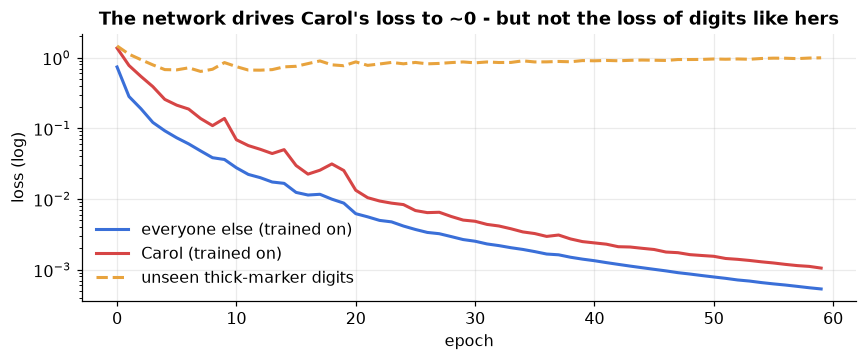

In [2]:
# Step 1: train the network, and record the loss as it learns
history = []

train.set_seed(0); model = lab.model_fn()
opt = nn.Adam(model.params, lr=1e-3)
rng = np.random.default_rng(0)
for epoch in range(lab.FIT["epochs"]):
    for b in train.batches(len(L.X_train), 64, rng):
        _, g = nn.cross_entropy(model.forward(L.X_train[b], keep_cache=True), L.y_train[b])
        opt.step(model.backward(g))
    history.append((nn.cross_entropy(model(L.Xr), L.yr)[0], nn.cross_entropy(model(L.Xf), L.yf)[0],
                    nn.cross_entropy(model(L.X_like_forget), L.y_like_forget)[0]))

h = np.array(history)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.semilogy(h[:, 0], color=viz.RETAIN, lw=2, label="everyone else (trained on)")
ax.semilogy(h[:, 1], color=viz.FORGET, lw=2, label="Carol (trained on)")
ax.semilogy(h[:, 2], color=viz.ACCENT, lw=2, ls="--", label="unseen thick-marker digits")
ax.set_xlabel("epoch"); ax.set_ylabel("loss (log)"); ax.legend(); ax.set_title("The network drives Carol's loss to ~0 - but not the loss of digits like hers")
plt.tight_layout(); plt.show()

Read the two red and orange curves together. Carol's own digits are pushed to almost zero loss, while unseen digits in
**the same style** stay far higher. The network has not just learned "thick digits" - it has learned **Carol's 40
digits specifically**. That is memorisation.

#### Step 2 : Show the issue - who memorises more ?

Let us line up every model from Problems 1-3 next to the network, all trained on the same data, and measure the same
thing : *how much better is the model on Carol's own digits than on unseen digits in her style ?* That gap is a simple,
honest memorisation score.

model                    Carol  unseen thick     gap    test
Naive Bayes (P1)         60.0%         61.3%   -1.3%   91.1%
k-NN, k=5 (P1)           75.0%         67.5%   +7.5%   98.3%
Logistic reg. (P2)       92.5%         77.5%  +15.0%   97.2%
RBF SVM (P3)            100.0%         87.5%  +12.5%   99.4%
Random forest (P3)      100.0%         70.0%  +30.0%   97.2%
Neural network (P4)     100.0%         77.5%  +22.5%   98.0%


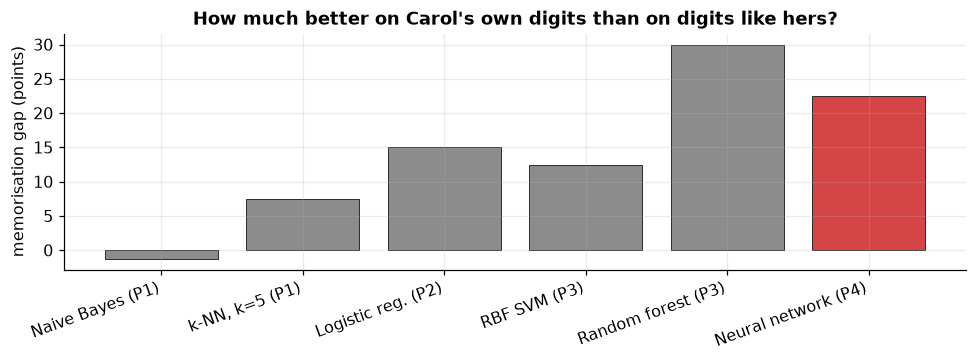

In [3]:
# Step 2: memorisation gap = accuracy on Carol's digits - accuracy on unseen thick-marker digits
acc = lambda m, X, y: float((m.predict(X) == y).mean())
contenders = {
    "Naive Bayes (P1)": classical.GaussianNB(1e-2).fit(L.X_train, L.y_train),
    "k-NN, k=5 (P1)": classical.KNN(5).fit(L.X_train, L.y_train),
    "Logistic reg. (P2)": classical.SoftmaxNewton(1.0).fit(L.X_train, L.y_train),
    "RBF SVM (P3)": SVC(kernel="rbf", C=10, gamma="scale").fit(L.X_train, L.y_train),
    "Random forest (P3)": classical.BaggedForest(50, seed=0).fit(L.X_train, L.y_train),
}
rows = []
for name, m in contenders.items():
    rows.append((name, acc(m, L.Xf, L.yf), acc(m, L.X_like_forget, L.y_like_forget), acc(m, L.X_test, L.y_test)))
rows.append(("Neural network (P4)", train.accuracy(model, L.Xf, L.yf), train.accuracy(model, L.X_like_forget, L.y_like_forget),
             train.accuracy(model, L.X_test, L.y_test)))

print(f"{'model':22s}{'Carol':>8s}{'unseen thick':>14s}{'gap':>8s}{'test':>8s}")
for n, a, b, t in rows:
    print(f"{n:22s}{a:8.1%}{b:14.1%}{a - b:+8.1%}{t:8.1%}")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar([r[0] for r in rows], [100 * (r[1] - r[2]) for r in rows],
       color=[viz.ORIGINAL] * (len(rows) - 1) + [viz.FORGET], edgecolor=viz.INK, lw=0.6)
ax.set_ylabel("memorisation gap (points)"); ax.set_title("How much better on Carol's own digits than on digits like hers?")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

Naive Bayes, the "average" model, does not memorise Carol at all. Every more flexible model does : the forest, the
network, logistic regression and the SVM are all far better on *her* digits than on digits *like* hers. **The more
flexible the model, the more it remembers individuals.** The network sits with the forest at the top - and unlike the
forest, it has no trees to rebuild separately.

#### A sharper lens : per-example memorisation

The gap above treats Carol as a block. Feldman (2020) defines memorisation **per example** :

`mem(x) = P[model is right on x | x was in training] − P[model is right on x | x was not in training]`

estimated by training several models with and without the example. Networks train in a third of a second here, so we
can afford it.

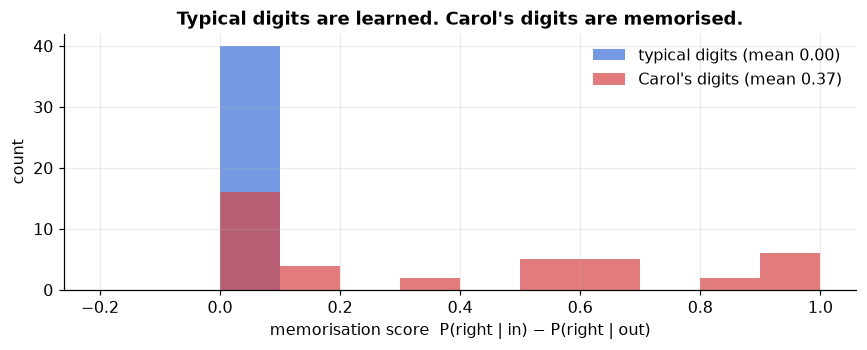

In [4]:
# Step 2b: Feldman-style memorisation for Carol's digits vs 40 random typical digits
typical = np.random.default_rng(1).choice(L.retain_idx, 40, replace=False)
probe = np.r_[L.forget_idx, typical]
drop = probe                                                      # train 'without' = remove all probe rows
keep = np.setdiff1d(np.arange(len(L.X_train)), drop)

seeds = range(6)
p_in = np.mean([train.predict(train.fit(lab.model_fn, L.X_train, L.y_train, seed=s, **lab.FIT), L.X_train[probe])
                == L.y_train[probe] for s in seeds], axis=0)
p_out = np.mean([train.predict(train.fit(lab.model_fn, L.X_train[keep], L.y_train[keep], seed=s, **lab.FIT), L.X_train[probe])
                 == L.y_train[probe] for s in seeds], axis=0)
mem = p_in - p_out
mem_carol, mem_typ = mem[: len(L.forget_idx)], mem[len(L.forget_idx):]

fig, ax = plt.subplots(figsize=(8, 3.3))
bins = np.linspace(-0.2, 1.0, 13)
ax.hist(mem_typ, bins=bins, color=viz.RETAIN, alpha=0.7, label=f"typical digits (mean {mem_typ.mean():.2f})")
ax.hist(mem_carol, bins=bins, color=viz.FORGET, alpha=0.7, label=f"Carol's digits (mean {mem_carol.mean():.2f})")
ax.set_xlabel("memorisation score  P(right | in) − P(right | out)"); ax.set_ylabel("count"); ax.legend()
ax.set_title("Typical digits are learned. Carol's digits are memorised."); plt.tight_layout(); plt.show()

Typical digits score ≈ 0 : the network gets them right whether or not they were in training, because thousands of
similar digits teach the same thing. Many of Carol's digits score high : they are right **only because they were
trained on**. That is the influence we must remove - and it is concentrated exactly in the data that is unusual.

> 🔴 **For practitioners :** this is Feldman's long-tail argument (`resources/papers/` - *Does Learning Require
> Memorization?*): in real data distributions, a large fraction of examples are rare sub-populations, and fitting them
> *requires* memorising them. Unlearning requests are not uniformly distributed - people with unusual data are both
> more memorised and more exposed.

#### Step 3 : Try the classical tricks

**Trick 1 (Problem 1) - subtract Carol's contribution.** For that we need to know *which weights* hold her. Train the
network twice from the **same seed** - once with Carol, once without - and compare every single weight.

In [5]:
# Trick 1: does Carol live in a few weights (like a sum or a forest's trees) ?
with_carol = train.fit(lab.model_fn, L.X_train, L.y_train, seed=0, **lab.FIT)
without_carol = train.fit(lab.model_fn, L.Xr, L.yr, seed=0, **lab.FIT)
diffs = np.concatenate([np.abs(a - b).ravel() for a, b in zip(with_carol.params, without_carol.params)])
print(f"weights that differ at all          : {np.mean(diffs > 0):.1%} of {diffs.size:,}")
print(f"weights that differ by > 1e-3       : {np.mean(diffs > 1e-3):.1%}")

weights that differ at all          : 94.1% of 85,002
weights that differ by > 1e-3       : 87.4%


Around **95% of all weights are different**. Carol is not stored *anywhere* in particular - she is smeared across all
~85,000 numbers, because every gradient step after her first mini-batch was taken from a slightly different place.
There is nothing to subtract. ❌

**Trick 2 (Problem 2) - one Newton step.** That needs the Hessian : an 85,000 × 85,000 matrix.

In [6]:
p = with_carol.n_params()
print(f"Hessian entries : {p**2:,}  ->  {p**2 * 4 / 1e9:,.0f} GB in float32")
print(f"for a 7B-parameter LLM : {(7e9)**2 * 2 / 1e18:,.0f} exabytes")

Hessian entries : 7,225,340,004  ->  29 GB in float32
for a 7B-parameter LLM : 98 exabytes


Too big even for this toy. But there is a deeper problem than size : Newton steps towards **the** optimum, and a
neural network does not have one. Look at how far apart two networks trained on the *same* data land, compared with
the effect of removing Carol :

In [7]:
# Trick 2 (deeper): is there a single optimum to step towards ?
other_seed = train.fit(lab.model_fn, L.X_train, L.y_train, seed=1, **lab.FIT)
flat = lambda m: np.concatenate([p.ravel() for p in m.params])
d_carol = np.linalg.norm(flat(with_carol) - flat(without_carol))
d_seed = np.linalg.norm(flat(with_carol) - flat(other_seed))
print(f"distance: same seed, with vs without Carol : {d_carol:8.2f}")
print(f"distance: same data, seed 0 vs seed 1      : {d_seed:8.2f}")
print(f"both seed-0 and seed-1 models reach test accuracy {train.accuracy(with_carol, L.X_test, L.y_test):.1%} / "
      f"{train.accuracy(other_seed, L.X_test, L.y_test):.1%}")

distance: same seed, with vs without Carol :     9.87
distance: same data, seed 0 vs seed 1      :    50.96
both seed-0 and seed-1 models reach test accuracy 98.0% / 98.7%


**Stop and notice what just happened.** Two equally good networks trained on *identical* data are further apart than
the with-Carol / without-Carol pair. There are countless equally good solutions; "the" retrained model is not a point
in weight space, it is a whole **distribution** of models. So :

- There is no single target to take a Newton step towards. ❌
- Comparing weights can never prove forgetting - the proof has to be about **behaviour**. (Problem 5.)
- The gold standard itself is a *band*, not a number. (Problem 6.)

**Trick 3 (Problem 3) - locality.** Retrain only what Carol touched ? Trick 1 already answered : she touched everything.
Unless we **design** the network the way we designed the user-aware forest - that is SISA, Problem 7. ❌ (for now)

#### Step 4 : Untrain - the only exact option left

In [8]:
# Step 4: retrain from scratch without Carol - every trick failed, so this is what remains
t0 = time.perf_counter()
retrained = train.fit(lab.model_fn, L.Xr, L.yr, seed=0, **lab.FIT)
t_retrain = time.perf_counter() - t0
print(f"{'':30s}{'original':>10s}{'retrained':>11s}")
for name, X, y in [("accuracy on Carol (D_f)", L.Xf, L.yf), ("accuracy on unseen thick", L.X_like_forget, L.y_like_forget),
                   ("accuracy on test", L.X_test, L.y_test)]:
    print(f"{name:30s}{train.accuracy(with_carol, X, y):10.1%}{train.accuracy(retrained, X, y):11.1%}")
print(f"\nretraining cost: {t_retrain:.2f} s here, for {lab.FIT['epochs']} epochs over {len(L.Xr):,} rows")

                                original  retrained
accuracy on Carol (D_f)           100.0%      55.0%
accuracy on unseen thick           77.5%      62.5%
accuracy on test                   98.0%      98.0%

retraining cost: 0.27 s here, for 60 epochs over 1,217 rows


#### Step 5 : Prove it - by behaviour, not by weights

After retraining, the model is right on Carol's digits about as often as on *unseen* digits in her style - her digits
get no special treatment any more. That behavioural equivalence is the only kind of proof a neural network allows.

The retrain cost 0.3 s here. GPT-scale pretraining runs cost millions of GPU-hours, and the deletion requests do not stop
coming. That gap - **exact but unaffordable** - is what Problems 6-11 attack.

----
#### OUTCOME :

| Classical handle | Did it survive in the network ? | Evidence |
|---|---|---|
| Subtract a sum (P1) | ❌ | ~100% of weights change when Carol is removed |
| Newton step / closed form (P2) | ❌ | Hessian is 85k × 85k; two seeds land further apart than with/without Carol |
| Locality (P3) | ❌ (unless designed in) | no weight is "Carol's" |
| **Retrain from scratch** | ✅ exact | but its cost scales with *everything you keep* |

And one new fact that changes how we must *prove* forgetting : the network **memorises atypical individuals** far more
than the classical models, and there is no unique "right" network to compare weights against.

#### Key Takeaways :

- Flexible models memorise individuals; atypical data (Carol) is memorised the most (Feldman's long tail).
- In a neural network every example changes every weight - nothing to subtract, no locality.
- Non-convexity means many equally good networks : the gold standard is a **distribution**, so proof must be
  **behavioural**.
- Retraining is still the exact answer - it is just too expensive at scale.

#### TASK :
1. Add `weight_decay=1e-3` to `lab.FIT` and re-run Step 2b. Does regularisation reduce Carol's memorisation score? At
   what cost in test accuracy?
2. Train with 20 epochs instead of 60. Plot memorisation gap against epochs (5, 10, 20, 60, 120). When does
   memorisation start?
3. Repeat the weight-difference experiment (Trick 1) but remove a single *typical* digit instead of Carol. Are fewer
   weights affected? Why not?
4. Replace the network with `MLP(64, 10, hidden=(32,))`. Does a smaller network memorise less?

#### ❓ Open question → Problem 5
We just said the proof must be about **behaviour**. So imagine you are an outsider with only query access to a model :
**could you tell whether Carol's data was used to train it?** If you can, the model is leaking - and you also have the
tool you need to check every unlearning method in this course.